In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# 데이터셋 로딩, RoBERTa 학습, 성능 평가에 필요한 라이브러리를 설치합니다.
!pip -q install transformers datasets accelerate scikit-learn

In [ ]:
import re
import ast
import html
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm

from pathlib import Path
from IPython.display import display, HTML
from datasets import load_dataset
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup,
)

In [ ]:
# Google Drive의 HC3_ko 폴더에 모델과 학습 기록을 저장합니다.
MODEL_DIR = Path("/content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko")
BEST_MODEL_PATH = MODEL_DIR / "HC3_ko_best_model.pt"


In [ ]:
MODEL_NAME = "klue/roberta-base"      # Hugging Face 사전학습 모델
DATASET_NAME = "nayohan/HC3-ko"      # Hugging Face 데이터셋

MAX_LEN = 512                        # 입력 최대 토큰 수; 긴 글은 잘림 (현재 모델 한계 512)
MAX_PAIRS = 8961                     # 사용할 질문-답변 쌍 최대 수

# MIN_CHARS = 20                     # 짧은 답변을 제외하려면 아래 필터와 함께 주석 해제
# human_answers = [a for a in human_answers if len(a) >= MIN_CHARS]
# chatgpt_answers = [a for a in chatgpt_answers if len(a) >= MIN_CHARS]

BATCH_SIZE = 16                      # 한 번에 학습할 글 수
NUM_WORKERS = 0                     # DataLoader 병렬 작업 수

EPOCHS = 10                           # 전체 데이터 반복 횟수
LR = 2e-5                            # 학습률
WEIGHT_DECAY = 0.01                 # 가중치 감쇠
WARMUP_RATIO = 0.10                 # 전체 학습 단계 중 Warmup 비율

SUSPICION_THRESHOLD = 0.50          # 문장별 의심 구역 표시 기준
CONTEXT_RADIUS = 1                  # 각 문장 점수 계산 시 포함할 앞뒤 문장 수

In [ ]:
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    DEVICE = torch.device("xpu")
else:
    DEVICE = torch.device("cpu")

print("DEVICE:", DEVICE)

DEVICE: cuda


In [ ]:
# 설정 셀의 모델 이름으로 Tokenizer를 불러와 글을 모델 입력으로 변환할 준비
# 모델과 함께 공개된 Tokenizer를 사용해야 토큰 ID가 맞음
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("모델:", MODEL_NAME)
print("Tokenizer:", type(tokenizer).__name__)
print("Vocab 크기:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/752k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

모델: klue/roberta-base
Tokenizer: BertTokenizer
Vocab 크기: 32000


# 데이터셋 준비

In [ ]:
# Hugging Face 원본 데이터셋의 구조와 질문 수를 먼저 확인
raw_dataset = load_dataset(
    DATASET_NAME,
    split="train",  # train 분할 하나만 제공됨
)

print(raw_dataset)
print("전체 질문 행 수:", len(raw_dataset))

# 이후 학습에는 질문과 두 종류의 답변만 사용
raw_dataset = raw_dataset.select_columns(
    ["question", "human_answers", "chatgpt_answers"]
)

README.md:   0%|          | 0.00/768 [00:00<?, ?B/s]

data/train-00000-of-00001-ebf02e9cac9ce0(…): reconstructing file:   0%|          |  0.00B / 42.1MB            

data/train-00000-of-00001-ebf02e9cac9ce0(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/24322 [00:00<?, ? examples/s]

Dataset({
    features: ['question', 'human_answers', 'chatgpt_answers', 'id', 'source'],
    num_rows: 24322
})
전체 질문 행 수: 24322


# 학습에 사용하는 데이터셋 컬럼

In [ ]:
# 문자열로 저장된 답변 목록을 실제 리스트로 바꾸어 답변만 추출
def parse_answers(value):
    # 데이터가 이미 목록으로 읽힌 경우
    if isinstance(value, list):
        answers = value

    elif isinstance(value, str):
        value = value.strip()

        if not value:
            return []

        if value.startswith("["):
            # "['답변1', '답변2']"처럼 저장된 문자열을 목록으로 변환
            try:
                answers = ast.literal_eval(value)
            except (ValueError, SyntaxError):
                return []
        else:
            # 일반 문자열이면 답변 하나로 처리
            answers = [value]

    else:
        return []

    if not isinstance(answers, list):
        return []

    # 빈 답변과 문자열이 아닌 값은 제외
    return [
        answer.strip()
        for answer in answers
        if isinstance(answer, str) and answer.strip()
    ]

# 지름길(Shortcut) 제거

In [ ]:
# 두 클래스 답변에 같은 규칙을 적용해 형식 흔적(URL 자리표시자, 구두점 공백)을 정리
def clean_text(text):
    text = html.unescape(text)

    # [ 링크 글자 ] ( URL_0 ) -> 링크 글자
    text = re.sub(r"\[\s*([^\]]*?)\s*\]\s*\(\s*URL_\d+\s*\)", r"\1", text)

    # 남은 URL 자리표시자 제거
    text = re.sub(r"\(?\s*URL_\d+\s*\)?", " ", text)

    # 구두점/닫는 괄호 앞 공백, 여는 괄호 뒤 공백 제거
    text = re.sub(r"\s+([.,!?;:%)\]])", r"\1", text)
    text = re.sub(r"([(\[])\s+", r"\1", text)

    # 연속된 공백을 하나로
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n\s*\n+", "\n", text)

    return text.strip()



In [ ]:
# 각 질문에서 사람 답변과 ChatGPT 답변을 한 개씩 골라 한 쌍으로 만듦

pairs = []

for row in raw_dataset:
    human_answers = [
        clean_text(answer)
        for answer in parse_answers(row["human_answers"])
    ]
    chatgpt_answers = [
        clean_text(answer)
        for answer in parse_answers(row["chatgpt_answers"])
    ]

    # human_answers = [a for a in human_answers if len(a) >= MIN_CHARS]
    # chatgpt_answers = [a for a in chatgpt_answers if len(a) >= MIN_CHARS]

    # 정리 후 비어 버린 답변만 제외합니다.
    human_answers = [a for a in human_answers if a]
    chatgpt_answers = [a for a in chatgpt_answers if a]

    # 사람과 ChatGPT 답변이 모두 있는 질문만 사용
    if not human_answers or not chatgpt_answers:
        continue

    # 클래스 균형을 위해 두 클래스에서 첫 번째 답변 하나씩 선택
    pairs.append({
        "question": str(row["question"]).strip(),
        "human_text": human_answers[0],
        "chatgpt_text": chatgpt_answers[0],
    })

pairs_df = pd.DataFrame(pairs)

print("사용 가능한 질문-답변 쌍:", len(pairs_df))

<unknown>:1: SyntaxWarning: invalid escape sequence '\e'
<unknown>:1: SyntaxWarning: invalid escape sequence '\P'
<unknown>:1: SyntaxWarning: invalid escape sequence '\ '
<unknown>:1: SyntaxWarning: invalid escape sequence '\ '
<unknown>:1: SyntaxWarning: invalid escape sequence '\ '
<unknown>:1: SyntaxWarning: invalid escape sequence '\L'
<unknown>:1: SyntaxWarning: invalid escape sequence '\D'
<unknown>:1: SyntaxWarning: invalid escape sequence '\S'


사용 가능한 질문-답변 쌍: 8961


In [ ]:
# 설정 셀의 MAX_PAIRS만큼 질문 쌍을 사용해 학습 시간을 조절합니다.
if len(pairs_df) > MAX_PAIRS:
    pairs_df = pairs_df.sample(n=MAX_PAIRS).reset_index(drop=True)

print("사용 질문 쌍:", len(pairs_df))
print("전체 답변 수:", len(pairs_df) * 2)

사용 질문 쌍: 8961
전체 답변 수: 17922


In [ ]:
# 셀 생략 가능
# 글자 수와 토큰 수를 비교해 MAX_LEN가 적당한지 확인
pairs_df["human_length"] = pairs_df["human_text"].str.len()
pairs_df["chatgpt_length"] = pairs_df["chatgpt_text"].str.len()

display(
    pairs_df[["human_length", "chatgpt_length"]].describe()
)

for column, name in [("human_text", "사람"), ("chatgpt_text", "ChatGPT")]:
    token_lengths = np.array([
        len(ids)
        for ids in tokenizer(pairs_df[column].tolist())["input_ids"]
    ])

    print(
        f"{name:8s} 토큰 수 | "
        f"중앙값 {np.median(token_lengths):.0f} | "
        f"90% {np.percentile(token_lengths, 90):.0f} | "
        f"MAX_LEN({MAX_LEN}) 초과 {np.mean(token_lengths > MAX_LEN) * 100:.1f}%"
    )

,human_length,chatgpt_length
count,8961.000000,8961.000000
mean,324.324406,459.288137
std,360.436911,165.391882
min,5.000000,16.000000
25%,112.000000,347.000000
50%,220.000000,458.000000
75%,401.000000,553.000000
max,10007.000000,1924.000000


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (573 > 512). Running this sequence through the model will result in indexing errors


사람       토큰 수 | 중앙값 112 | 90% 349 | MAX_LEN(512) 초과 4.3%
ChatGPT  토큰 수 | 중앙값 227 | 90% 326 | MAX_LEN(512) 초과 0.4%


# 데이터 분할

In [ ]:
# 같은 질문이 학습과 평가에 섞이지 않도록 질문 단위로 학습 데이터를 나눔
splitter_1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,  # 전체 질문의 20%를 검증·테스트용으로 분리
)

train_idx, temp_idx = next(
    splitter_1.split(
        pairs_df,
        groups=pairs_df["question"],
    )
)

train_pairs = pairs_df.iloc[train_idx].reset_index(drop=True)
temp_pairs = pairs_df.iloc[temp_idx].reset_index(drop=True)

# 남은 질문을 다시 반씩 나누어 검증용과 최종 평가용으로 사용
splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,  # 분리된 20%를 반씩 나누어 검증·테스트 각 10%
)

val_idx, test_idx = next(
    splitter_2.split(
        temp_pairs,
        groups=temp_pairs["question"],
    )
)

val_pairs = temp_pairs.iloc[val_idx].reset_index(drop=True)
test_pairs = temp_pairs.iloc[test_idx].reset_index(drop=True)

print("Train 질문 쌍:", len(train_pairs))
print("Val   질문 쌍:", len(val_pairs))
print("Test  질문 쌍:", len(test_pairs))

Train 질문 쌍: 7156
Val   질문 쌍: 904
Test  질문 쌍: 901


In [ ]:
# 세 분할에 같은 질문이 중복되지 않는지 검사
train_questions = set(train_pairs["question"])
val_questions = set(val_pairs["question"])
test_questions = set(test_pairs["question"])

# 중복 질문이 있으면 평가가 과대 추정되므로 실행 중단
assert train_questions.isdisjoint(val_questions)
assert train_questions.isdisjoint(test_questions)
assert val_questions.isdisjoint(test_questions)

print("분할 사이에 겹치는 질문이 없습니다.")

분할 사이에 겹치는 질문이 없습니다.


In [ ]:
# 답변 쌍을 개별 글과 사람(0)/ChatGPT(1) 라벨로 바꿈
LABEL_NAMES = ["HUMAN", "CHATGPT"]


def make_classification_df(pair_df):
    rows = []

    for _, row in pair_df.iterrows():
        rows.append({
            "text": row["human_text"],
            "label": 0,  # 사람 답변
        })
        rows.append({
            "text": row["chatgpt_text"],
            "label": 1,  # ChatGPT 답변
        })

    return pd.DataFrame(rows)


train_df = make_classification_df(train_pairs)
val_df = make_classification_df(val_pairs)
test_df = make_classification_df(test_pairs)

print("Train 글:", len(train_df))
print("Val   글:", len(val_df))
print("Test  글:", len(test_df))

Train 글: 14312
Val   글: 1808
Test  글: 1802


# Dataset / DataLoader

In [ ]:
# 글을 미리 토큰화해 두고, padding은 배치를 만들 때 수행하는 Dataset을 정의
class TextClassificationDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.labels = dataframe["label"].tolist()

        # padding 없이 잘라내기만 함 (padding은 collator가 배치 단위로 수행)
        self.encoded = tokenizer(
            dataframe["text"].tolist(),
            truncation=True,
            max_length=max_length,
            return_token_type_ids=False,
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {
            "input_ids": self.encoded["input_ids"][index],
            "attention_mask": self.encoded["attention_mask"][index],
            "labels": self.labels[index],
        }

In [ ]:
# 학습/검증/평가 Dataset과 배치 단위 padding을 담당할 collator를 만듦
train_dataset = TextClassificationDataset(train_df, tokenizer, MAX_LEN)
val_dataset = TextClassificationDataset(val_df, tokenizer, MAX_LEN)
test_dataset = TextClassificationDataset(test_df, tokenizer, MAX_LEN)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    return_tensors="pt",
)

print("Train:", len(train_dataset))
print("Val  :", len(val_dataset))
print("Test :", len(test_dataset))

Train: 14312
Val  : 1808
Test : 1802


In [ ]:
# 설정 셀의 배치 크기와 작업 수로 DataLoader를 만듦
loader_kwargs = dict(
    batch_size=BATCH_SIZE,
    collate_fn=collator,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)

train_loader = DataLoader(
    train_dataset,
    shuffle=True,   # 학습할 때만 순서를 섞음
    **loader_kwargs,
)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

print("Train batches:", len(train_loader))
print("Val   batches:", len(val_loader))
print("Test  batches:", len(test_loader))

Train batches: 895
Val   batches: 113
Test  batches: 113


# 모델 (RoBERTa + Classification Head)

In [ ]:
# 사전학습 RoBERTa에 2개 클래스용 분류 헤드를 붙여 모델을 준비
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label={i: name for i, name in enumerate(LABEL_NAMES)},
    label2id={name: i for i, name in enumerate(LABEL_NAMES)},
).to(DEVICE)

model

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: klue/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(32000, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
             

# 학습 설정

In [ ]:
# 설정 셀의 학습 값으로 Optimizer와 Scheduler를 만듦
# bias, LayerNorm은 weight decay에서 제외
no_decay = ["bias", "LayerNorm.weight"]
optimizer_grouped_parameters = [
    {
        "params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
        "weight_decay": 0.0,
    },
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, lr=LR)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps,
)

print("Total steps :", total_steps)
print("Warmup steps:", warmup_steps)
print(optimizer)

Total steps : 8950
Warmup steps: 895
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 2e-05
    lr: 0.0
    maximize: False
    weight_decay: 0.01

Parameter Group 1
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    initial_lr: 2e-05
    lr: 0.0
    maximize: False
    weight_decay: 0.0
)


# AMP(Automatic Mixed Precision)

In [ ]:
use_amp = (DEVICE.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
print("AMP enabled: ", use_amp)

AMP enabled:  True


### 평가 지표
- Positive 클래스 = ChatGPT
- Precision: ChatGPT라고 판정한 글 중 실제 ChatGPT 비율 → 낮으면 사람 글을 AI로 오판
- Recall: 실제 ChatGPT 글 중 잡아낸 비율 → 낮으면 AI 글을 놓침
- F 점수: Precision과 Recall의 조화 평균 → Best model 선택 기준

In [ ]:
# 정답과 예측을 비교해 전체 분류 지표를 계산
def compute_metrics(labels, predictions):
    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(labels, predictions, zero_division=0),
        "recall": recall_score(labels, predictions, zero_division=0),
        "f1": f1_score(labels, predictions, zero_division=0),
    }

In [ ]:
@torch.no_grad()
def evaluate(model, loader, device):
    model.eval()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for batch in loader:
        batch = {key: value.to(device, non_blocking=True) for key, value in batch.items()}

        with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=(device.type == "cuda")):
            outputs = model(**batch)

        logits = outputs.logits.float()
        predictions = logits.argmax(dim=1)

        batch_size = batch["labels"].size(0)
        total_loss += outputs.loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(batch["labels"].cpu().tolist())
        all_predictions.extend(predictions.cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        **compute_metrics(all_labels, all_predictions),
    }

In [ ]:
# 학습 배치의 예측을 모아 Train Loss, Accuracy, Precision, Recall을 계산
def train_one_epoch(model, loader, optimizer, scheduler, scaler, device):
    model.train()

    total_loss = 0.0
    total_samples = 0
    all_labels = []
    all_predictions = []

    for batch in tqdm(loader, desc="Train", leave=True):
        batch = {key: value.to(device, non_blocking=True) for key, value in batch.items()}

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda"),
        ):
            outputs = model(**batch)
            loss = outputs.loss

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()
        scheduler.step()  # Warmup/Linear scheduler는 배치마다 갱신

        batch_size = batch["labels"].size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(batch["labels"].detach().cpu().tolist())
        all_predictions.extend(outputs.logits.detach().argmax(dim=1).cpu().tolist())

    return {
        "loss": total_loss / total_samples,
        **compute_metrics(all_labels, all_predictions),
    }

# 학습

In [ ]:
# 설정 셀에서 선택한 폴더를 생성해 학습 결과를 저장할 준비
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("결과 저장 위치:", MODEL_DIR)

결과 저장 위치: /content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko


In [ ]:
history = {
    "train_loss": [],
    "train_accuracy": [],
    "train_precision": [],
    "train_recall": [],
    "train_f1": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_precision": [],
    "val_recall": [],
    "val_f1": [],
}

best_f1 = -1.0
best_epoch = 0
training_start = time.time()

for epoch in range(1, EPOCHS + 1):
    epoch_start = time.time()

    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
        scheduler,
        scaler,
        DEVICE,
    )

    val_metrics = evaluate(
        model,
        val_loader,
        DEVICE,
    )

    for key in ["loss", "accuracy", "precision", "recall", "f1"]:
        history[f"train_{key}"].append(train_metrics[key])
    for key in ["loss", "accuracy", "precision", "recall", "f1"]:
        history[f"val_{key}"].append(val_metrics[key])

    is_best = val_metrics["f1"] > best_f1
    if is_best:
        best_f1 = val_metrics["f1"]
        best_epoch = epoch

        # 가장 좋은 모델의 가중치만 하나의 PT 파일로 저장
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    # 완료된 에폭의 평균 시간을 이용해 남은 에폭의 소요 시간을 추정
    epoch_seconds = time.time() - epoch_start
    remaining_seconds = (time.time() - training_start) / epoch * (EPOCHS - epoch)
    remaining_minutes, remaining_seconds_part = divmod(int(remaining_seconds), 60)

    print(f"[{epoch:02d}/{EPOCHS}] 에폭 소요={epoch_seconds:.1f}초 | 예상 남은 시간={remaining_minutes}분 {remaining_seconds_part}초")
    print(
        f"  Train | Loss={train_metrics['loss']:.4f} | "
        f"Acc={train_metrics['accuracy']*100:.2f}% | "
        f"P={train_metrics['precision']:.4f} | "
        f"R={train_metrics['recall']:.4f} | "
        f"F1={train_metrics['f1']:.4f}"
    )
    print(
        f"  Val   | Loss={val_metrics['loss']:.4f} | "
        f"Acc={val_metrics['accuracy']*100:.2f}% | "
        f"P={val_metrics['precision']:.4f} | "
        f"R={val_metrics['recall']:.4f} | "
        f"F1={val_metrics['f1']:.4f}"
    )

    if is_best:
        print(f"  -> Best model 저장: {BEST_MODEL_PATH}")

print(f"\nBest Validation F1: {best_f1:.4f} (epoch {best_epoch})")

Train:   0%|          | 0/895 [00:00<?, ?it/s]

[01/10] 에폭 소요=80.0초 | 예상 남은 시간=11분 59초
  Train | Loss=0.2195 | Acc=90.81% | P=0.9301 | R=0.8826 | F1=0.9057
  Val   | Loss=0.2297 | Acc=94.41% | P=0.9011 | R=0.9978 | F1=0.9470
  -> Best model 저장: /content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko/HC3_ko_best_model.pt


Train:   0%|          | 0/895 [00:00<?, ?it/s]

[02/10] 에폭 소요=64.7초 | 예상 남은 시간=9분 38초
  Train | Loss=0.0675 | Acc=98.33% | P=0.9835 | R=0.9831 | F1=0.9833
  Val   | Loss=0.1443 | Acc=96.90% | P=0.9435 | R=0.9978 | F1=0.9699
  -> Best model 저장: /content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko/HC3_ko_best_model.pt


Train:   0%|          | 0/895 [00:00<?, ?it/s]

...

[08/10] 에폭 소요=63.8초 | 예상 남은 시간=2분 10초
  Train | Loss=0.0021 | Acc=99.96% | P=0.9996 | R=0.9996 | F1=0.9996
  Val   | Loss=0.1329 | Acc=98.45% | P=0.9740 | R=0.9956 | F1=0.9847
  -> Best model 저장: /content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko/HC3_ko_best_model.pt


Train:   0%|          | 0/895 [00:00<?, ?it/s]

[09/10] 에폭 소요=62.7초 | 예상 남은 시간=1분 5초
  Train | Loss=0.0015 | Acc=99.98% | P=0.9997 | R=0.9999 | F1=0.9998
  Val   | Loss=0.1893 | Acc=97.73% | P=0.9576 | R=0.9989 | F1=0.9778


Train:   0%|          | 0/895 [00:00<?, ?it/s]

[10/10] 에폭 소요=62.5초 | 예상 남은 시간=0분 0초
  Train | Loss=0.0006 | Acc=99.99% | P=0.9997 | R=1.0000 | F1=0.9999
  Val   | Loss=0.1637 | Acc=98.29% | P=0.9678 | R=0.9989 | F1=0.9831

Best Validation F1: 0.9847 (epoch 8)


In [ ]:
# Epoch별 기록을 표로 정리합니다. (TXT 저장에서 사용하므로 실행 필요)
history_df = pd.DataFrame(history)
history_df.insert(0, "epoch", range(1, len(history_df) + 1))

display(history_df)

,epoch,train_loss,train_accuracy,train_precision,train_recall,train_f1,val_loss,val_accuracy,val_precision,val_recall,val_f1
0,1,0.219488,0.908119,0.930054,0.882616,0.905714,0.229689,0.944137,0.901099,0.997788,0.946982
1,2,0.067514,0.983301,0.983503,0.983091,0.983297,0.144271,0.969027,0.943515,0.997788,0.969892
2,3,0.030297,0.993712,0.994264,0.993153,0.993708,0.083095,0.982854,0.987709,0.977876,0.982768
3,4,0.019451,0.996297,0.996366,0.996227,0.996297,0.123848,0.976217,0.955556,0.998894,0.976744
4,5,0.009158,0.998044,0.997765,0.998323,0.998044,0.282836,0.963496,0.932851,0.998894,0.964744
5,6,0.007053,0.998742,0.998603,0.998882,0.998742,0.301952,0.958518,0.924258,0.998894,0.960128
6,7,0.004572,0.998882,0.998882,0.998882,0.998882,0.213733,0.974558,0.952532,0.998894,0.975162
7,8,0.002096,0.999581,0.999581,0.999581,0.999581,0.132921,0.984513,0.974026,0.995575,0.984683
8,9,0.001518,0.999790,0.999721,0.999860,0.999790,0.189254,0.977323,0.957582,0.998894,0.977802
9,10,0.000595,0.999860,0.999721,1.000000,0.999860,0.163714,0.982854,0.967846,0.998894,0.983125


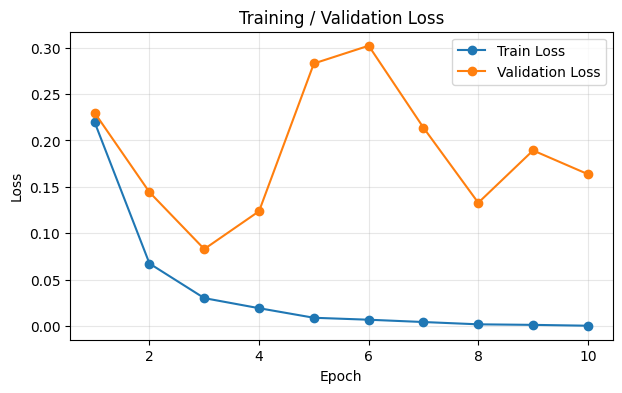

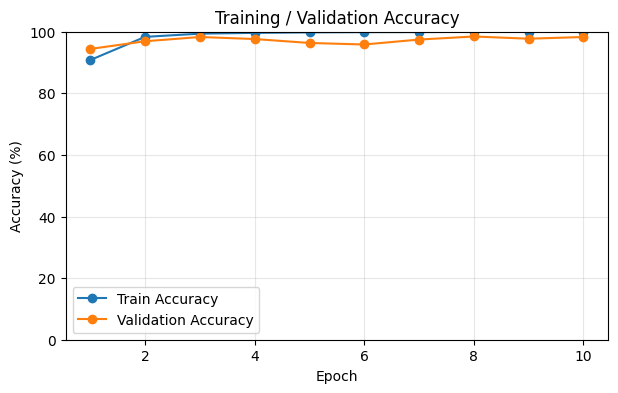

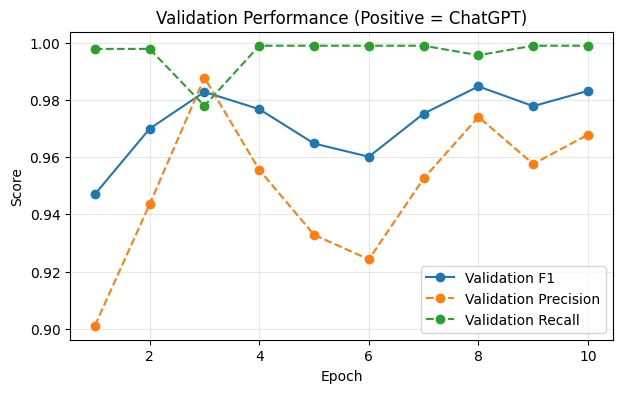

In [ ]:
epochs = history_df["epoch"]

plt.figure(figsize=(7, 4))
plt.plot(epochs, history_df["train_loss"], marker="o", label="Train Loss")
plt.plot(epochs, history_df["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Train/Val Accuracy를 함께 그려 학습과 검증 성능을 비교합니다.
plt.figure(figsize=(7, 4))
plt.plot(epochs, history_df["train_accuracy"] * 100, marker="o", label="Train Accuracy")
plt.plot(epochs, history_df["val_accuracy"] * 100, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training / Validation Accuracy")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(epochs, history_df["val_f1"], marker="o", label="Validation F1")
plt.plot(epochs, history_df["val_precision"], marker="o", linestyle="--", label="Validation Precision")
plt.plot(epochs, history_df["val_recall"], marker="o", linestyle="--", label="Validation Recall")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance (Positive = ChatGPT)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Test 평가

In [ ]:
# 저장한 가중치를 같은 모델 구조에 불러옵니다. Tokenizer는 앞에서 불러온 것을 재사용
best_model = AutoModelForSequenceClassification.from_config(model.config)
best_model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location="cpu", weights_only=True))
best_model = best_model.to(DEVICE)
best_tokenizer = tokenizer
best_model.eval()

print("Best epoch:", best_epoch)
print("Best validation F1:", f"{best_f1:.4f}")
print("클래스:", best_model.config.id2label)

Best epoch: 8
Best validation F1: 0.9847
클래스: {0: 'HUMAN', 1: 'CHATGPT'}


In [ ]:
test_result = evaluate(best_model, test_loader, DEVICE)

print(f"Accuracy : {test_result['accuracy']:.4f}")
print(f"Precision: {test_result['precision']:.4f}")
print(f"Recall   : {test_result['recall']:.4f}")
print(f"F1-score : {test_result['f1']:.4f}")

Accuracy : 0.9856
Precision: 0.9740
Recall   : 0.9978
F1-score : 0.9857


In [ ]:
# Epoch별 Train/Val 지표를 읽기 쉬운 TXT 파일로 저장
history_path = MODEL_DIR / "history.txt"

with open(history_path, "w", encoding="utf-8") as file:
    for _, row in history_df.iterrows():
        file.write(f"Epoch {int(row['epoch'])}\n")

        for split in ("train", "val"):
            file.write(
                f"{split.upper():5s} | "
                f"Acc={row[split + '_accuracy']:.4f} | "
                f"Loss={row[split + '_loss']:.4f} | "
                f"Precision={row[split + '_precision']:.4f} | "
                f"Recall={row[split + '_recall']:.4f} | "
                f"F1={row[split + '_f1']:.4f}\n"
            )

        file.write("\n")

print("학습 기록 저장 완료:", history_path)

학습 기록 저장 완료: /content/drive/MyDrive/Colab Notebooks/train_result/HC3_ko/history.txt


# 직접 판별해 보기


In [ ]:
# 글 여러 개를 한 번에 토큰화해 ChatGPT(1) 확률을 계산
@torch.no_grad()
def predict_scores(texts):
    encoded = best_tokenizer(
        texts,
        truncation=True,
        max_length=MAX_LEN,
        padding=True,
        return_token_type_ids=False,
        return_tensors="pt",
    ).to(DEVICE)

    logits = best_model(**encoded).logits.float()
    return torch.softmax(logits, dim=1)[:, 1].cpu().tolist()


def split_sentences(text):
    # 마침표, 물음표, 느낌표 뒤 공백 또는 줄바꿈 기준으로 문장 분리
    pieces = re.split(r"(?<=[.!?])\s+|\n+", text.strip())
    return [piece.strip() for piece in pieces if piece.strip()]

In [ ]:
# 전체 글 의심 점수와 문장별(앞뒤 문맥 포함) 점수를 화면에 표시
def show_detection(text):
    text = clean_text(text)  # 학습 데이터와 같은 정리 규칙 적용
    if not text:
        raise ValueError("검사할 글을 입력")

    sentences = split_sentences(text)


    # 각 문장과 앞뒤 문장을 묶어 한 번에 점수 계산
    contexts = [
        " ".join(sentences[max(0, i - CONTEXT_RADIUS): i + CONTEXT_RADIUS + 1])
        for i in range(len(sentences))
    ]
    local_scores = predict_scores(contexts)

    # 여기부터 추가
    score = sum(local_scores) / len(local_scores)
    print(f"전체 의심 점수(문장별 평균): {score * 100:.2f}%")

    print("\n문장별 의심 점수:")
    blocks = []
    for sentence, local_score in zip(sentences, local_scores):
        color = "#ffe0e0" if local_score >= SUSPICION_THRESHOLD else "#e8f3e8"
        blocks.append(
            f'<div style="background:{color}; padding:8px; margin:5px 0; border-radius:5px;">'
            f'{html.escape(sentence)} <b>({local_score * 100:.1f}%)</b>'
            f'</div>'
        )

    display(HTML("".join(blocks)))

In [ ]:
# 직접 작성한 글을 넣어 판별 결과를 확인
my_text = """

이번엔 시로 간다.

시인 나태
자세히 보아야 예쁘다.
오래 보아야 사랑스럽다
너도 그렇다.

시인 윤동주
산모퉁이를 돌아 논가 외딴 우물을 홀로 찾아가선
가만히 들여다 봅니다.
우물 속에는 달이 밝고 구름이 흐르고 하늘이
펼치고 파아란 바람이 불고 가을이 있습니다.
그리고 한 사나이가 있습니다
어쩐지 그 사나이가 미워져 돌아갑니다.
돌아가다 생각하니 그 사나이가 가엾어집니다.
도로 가 들여다 보니 사나이는 그대로 있습니다.
다시 그 사나이가 미워져 돌아갑니다.
돌아가다 생각하니 그 사나이가 그리워집니다.
우물 속에는 달이 밝고 구름이 흐르고 하늘이
펼치고 파아란 바람이 불고 가을이 있고
追憶처럼 사나이가 있습니다.

어느 정도 걸러지는 것 같음

"""

show_detection(my_text)

전체 의심 점수(문장별 평균): 0.00%

문장별 의심 점수:


# 너 그냥 누가 봐도 지피티인거 알 수 있게 짧은 글 하나 써봐
현대 사회는 빠르게 변화하고 있으며, 기술의 발전은 우리의 일상생활에 다양한 영향을 미치고 있다.
특히 인공지능은 교육, 의료, 산업 등 여러 분야에서 활용되며 효율성과 생산성을 향상시키고 있다.
앞으로도 인공지능 기술은 지속적으로 발전할 것으로 예상되며, 이를 올바르게 활용하기 위한 윤리적 기준과 사회적 논의가 함께 이루어져야 할 것이다.

------------------------------------------------------------------------------

# 아무 글이나 써봐
창밖으로 햇빛이 천천히 기울기 시작했다. 바쁘게 지나가던 사람들의 발걸음도 어느새 조금씩 느려졌고, 거리에는 따뜻한 바람이 스쳐 지나갔다.
특별한 일이 있는 하루는 아니었지만, 그런 평범한 순간들이 모여 일상이 된다.
우리는 종종 큰 목표만 바라보지만, 오늘 마신 한 잔의 커피와 짧은 대화, 잠시 올려다본 하늘처럼 사소한 장면들도 시간이 지나면 오래 기억에 남는 추억이 된다.
그래서 오늘도 거창한 계획보다 지금 이 순간을 충실히 보내는 것이 가장 의미 있는 선택일지 모른다.

------------------------------------------------------------------------------

# 침팬지와 사람 비교하는 글 작성
침팬지와 사람은 모두 영장류에 속하며 유전적으로 매우 가까운 관계를 가지고 있다.
사람은 침팬지와 약 98.8%의 DNA를 공유하지만, 진화 과정에서 신체 구조와 인지 능력, 사회적 행동에서 뚜렷한 차이가 나타났다.
신체적으로 침팬지는 팔이 다리보다 길어 나무를 오르거나 주먹을 짚고 이동하는 데 적합한 반면,
사람은 다리가 길고 골반과 척추가 직립보행에 맞게 발달하여 장거리 이동이 가능하다.
또한 사람의 손은 정교한 작업을 수행하기에 적합하도록 발달해 다양한 도구를 만들고 사용할 수 있다.
인지 능력에서도 차이가 있다. 침팬지는 나뭇가지나 돌을 이용해 먹이를 얻는 등 도구를 사용할 수 있으며, 간단한 문제를 해결하거나 협력 행동을 보인다.
반면 사람은 언어를 사용하여 복잡한 정보를 전달하고, 추상적인 사고와 계획 수립, 과학과 예술 활동을 수행할 수 있다.
사회 구조 역시 다르다. 침팬지는 무리를 이루어 생활하며 서열을 중심으로 관계를 형성하지만,
사람은 가족과 공동체를 넘어 국가와 문명을 이루고 법과 문화, 교육 등의 체계를 발전시켜 왔다.
결과적으로 침팬지와 사람은 공통 조상에서 진화한 가까운 종이지만, 직립보행, 언어 능력, 높은 수준의 사고력, 그리고 복잡한 사회를 형성하는 능력은 사람을 다른 영장류와 구별하는 가장 큰 특징이라고 할 수 있다

------------------------------------------------------------------------------

# 내 답변
사람과 침팬지는 딱 봐도 외적인 모습이 다르다.
하는 행동도 다를뿐더러 그냥 다르다.
같다고 하면 님 침팬지.
할 말도 없고 또 무슨 얘기를 해야 되나 싶다고 하다.
AI가 썼다고 한번 해봐라 궁금하다.
죽어도 안 나오네 더 길어야 되나 얼마나 더 길어야 이걸 AI라고 생각할까?
노래 가사나 적어볼까.
언젠가 우리-김재민
뜨겁게 하나를 소리 내 외치던 젊음의 숨결 무엇도 두려울 것 없던 한잦의 푸르름으로 먼 훗날 또 다른 오르막 위에서
뒤돌아보면 언제나 오늘을 살아낼 이유가 되어줄 거야. 영원토록
의심 0% 확인

------------------------------------------------------------------------------

소년 만화- Qwer
기적 같이 내린 별빛 아래 품었던 꿈들 여기저기 헤매이다 흩어져버린 눈물이
은하수를 건너 밝게 빛을 낼 거야 분명, 수많은 밤을 견딘 마음은 활짝 피어나

1440 - 허각
하루 1440번 계속 니가 생각나. 아 하이라이트 아니네
널 이렇게 사랑한 나보다 나를 사랑하는 니가 됐으면 내 머리속에 사는 그대가 하늘 위를 걷는 날 봤으면
널 이렇게 바라본 나보다 나만 바라보는 니가 됐으면 너를 기다리는 지금 이상한 떨림이 나를 더 설레게 해
오늘은 뭐가 될 거 같은 DAY

젊은날 - MC몽
반짝이던 그 눈 함께 걸음 맞추던 찬란한 그 순간 시간 속에 다 모두 잊어가도 여진히 가슴 깊이 남아 스쳐 지난 우리 함꼐 길을 걸으면
그리운 그날 울고 웃던 밤 다시 가슴이 차올라 내 젊은날

노래는 다 사람이 썼나??

------------------------------------------------------------------------------

이번엔 시로 간다.

시인 나태
자세히 보아야 예쁘다.
오래 보아야 사랑스럽다
너도 그렇다.

시인 윤동주
산모퉁이를 돌아 논가 외딴 우물을 홀로 찾아가선
가만히 들여다 봅니다.
우물 속에는 달이 밝고 구름이 흐르고 하늘이
펼치고 파아란 바람이 불고 가을이 있습니다.
그리고 한 사나이가 있습니다
어쩐지 그 사나이가 미워져 돌아갑니다.
돌아가다 생각하니 그 사나이가 가엾어집니다.
도로 가 들여다 보니 사나이는 그대로 있습니다.
다시 그 사나이가 미워져 돌아갑니다.
돌아가다 생각하니 그 사나이가 그리워집니다.
우물 속에는 달이 밝고 구름이 흐르고 하늘이
펼치고 파아란 바람이 불고 가을이 있고
追憶처럼 사나이가 있습니다.

어느 정도 걸러지는 것 같음